# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Telco Customer Churn - Kaggle|
| что значит одна строка | Один клиент телеком-компании |
| цель (столбец) | Churn |
| тип задачи | классификация  |
| метрика | Accuracy, дополнительно F1-score |
| кому и зачем нужен такой прогноз | Телеком-компании,чтобы заранее находить клиентов,которые могут уйти, и удерживать их |

In [2]:
DATA_URL = ""   # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = "Churn"     # имя столбца-цели

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive (1).zip


In [4]:
import zipfile
import os
with zipfile.ZipFile("archive.zip", "r") as zip_ref:
  zip_ref.extractall("telco_data")
os.listdir("telco_data")

['WA_Fn-UseC_-Telco-Customer-Churn.csv']

In [5]:
df = pd.read_csv("telco_data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Размер таблицы:", df.shape)
display(df.head())
df.info()

raw = df.copy()

Размер таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize = True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


**Вывод.** В датасете 7043 клиента и 21 столбец. Большинство клиентов остались  (73,5%), а 26,5% ушли. Столбец TotalCharges нужно перевести в числовой формат.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [7]:
print("Количество полных дублей:", raw.duplicated().sum())

Количество полных дублей: 0


In [8]:
df = raw.copy()

**Вывод.** Полных дубликатов не обнаружено. Все строки оставлены без изменений.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [9]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    return pd.DataFrame({
        "negative_tenure": d["tenure"] < 0,
        "negative_monthly_charges":
d["MonthlyCharges"] < 0,
        "wrong_senior_citizen":
-d["SeniorCitizen"].isin([0, 1])
    })

In [10]:
flags = check_rules(raw)
print(flags.sum())


negative_tenure             0
negative_monthly_charges    0
wrong_senior_citizen        0
dtype: int64


In [11]:
print(raw.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [12]:
for col in raw.select_dtypes(include = "object"):
  print(col,raw[col].value_counts(dropna = False).head(10))



customerID customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
Name: count, dtype: int64
gender gender
Male      3555
Female    3488
Name: count, dtype: int64
Partner Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents Dependents
No     4933
Yes    2110
Name: count, dtype: int64
PhoneService PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
OnlineBackup OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count

In [13]:
print("Обычные пропуски:")
print(raw.isna().sum())
print("Пустые значения TotalCharges:")
print((raw["TotalCharges"].astype(str).str.strip() == "").sum())

Обычные пропуски:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Пустые значения TotalCharges:
11


In [14]:
raw[raw["TotalCharges"].astype(str).str.strip() == ""].head(15)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [15]:
import numpy as np
raw["TotalCharges"] = pd.to_numeric(raw["TotalCharges"],errors = "coerce")
print("Пропуски:", raw["TotalCharges"].isna().sum())

Пропуски: 11


In [16]:
# Решение: пропуски в TotalCharges оставляем как NaN до проверки причин.
# Журнал: найдено 11 пропусков

**Вывод.**В столбце TotalCharges обнаружено 11 пропусков. Обычных пропусков в остальных стобцах нет. Необходимо проверить причины и выбрать способ обработки.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [17]:
raw.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [18]:
raw.groupby(raw["TotalCharges"].isna())["Churn"].value_counts()

TotalCharges  Churn
False         No       5163
              Yes      1869
True          No         11
Name: count, dtype: int64

In [19]:
raw["TotalCharges"] = raw["TotalCharges"].fillna(0)
print("Заполнено пропусков:", raw["TotalCharges"].isna().sum())

Заполнено пропусков: 0


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |

| TotalCharges | 11 | нет | заполняем 0 | клиенты только подключились (tenure = 0) |

**Вывод.** Найдено 11 пропусков в TotalCharges. Они заменены на 0, так как у этих клиентов еще не было начислений

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [20]:
print(raw.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [21]:
raw["tenure"] = pd.to_numeric(raw["tenure"],errors = "coerce")
raw["MonthlyCharges"] = pd.to_numeric(raw["MonthlyCharges"],errors = "coerce")
print(raw[["tenure","MonthlyCharges","TotalCharges"]].dtypes)

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


In [22]:
# в датасете нет столбца с датами.

**Вывод.** Данные в стобцах tenure, MonthlyCharges, TotalCharges были в текстовом формате. Я преобразовал их в числовой при помощи pd.to_numeric(). Столбца с датами нет.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [23]:
print(raw.select_dtypes(include = "number").columns.tolist())

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [24]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
  print(col)
  print(raw[col].describe())

tenure
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64
MonthlyCharges
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64
TotalCharges
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


In [25]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
  q1 = raw[col].quantile(0.25)
  q3 = raw[col].quantile(0.75)
  iqr = q3 -q1
  low = q1 -1.5 * iqr
  high = q1 + 1.5 *iqr
  print(col,"Выбросы:",((raw[col] < low)|(raw[col] > high)).sum())

tenure Выбросы: 0
MonthlyCharges Выбросы: 13
TotalCharges Выбросы: 940


**Вывод.** tenure - выбросов нет. В MonthlyCharges - 13. В TotalCharges - 940.Это могут быть реальные редкие значения, поэтому удалять их не нужно.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

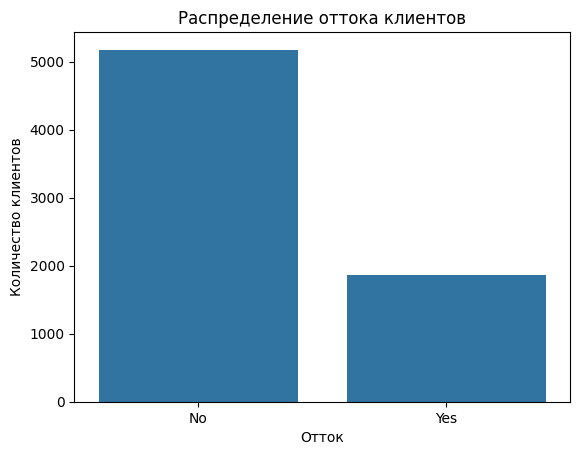

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=raw, x = "Churn")
plt.title("Распределение оттока клиентов")
plt.xlabel("Отток")
plt.ylabel("Количество клиентов")
plt.show()

**Что видно на графике 1.** Большинство клиентов остаются с компанией.

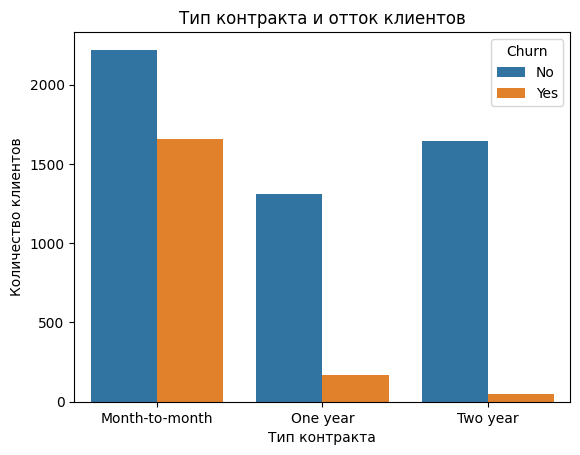

In [27]:
sns.countplot(data=raw, x="Contract",hue="Churn")
plt.title("Тип контракта и отток клиентов")
plt.xlabel("Тип контракта")
plt.ylabel("Количество клиентов")
plt.show()

**Что видно на графике 2.** При помесячном контракте отток клиентов самый высокий. Долгосрочные контракты помогают удерживать клиентов.

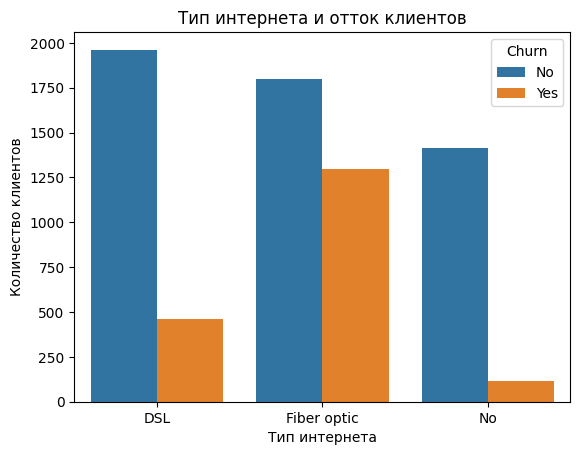

In [28]:
sns.countplot(data=raw, x="InternetService", hue="Churn")
plt.title("Тип интернета и отток клиентов")
plt.xlabel("Тип интернета")
plt.ylabel("Количество клиентов")
plt.show()

**Что видно на графике 3.** Тип интернета влияет на отток: среди пользователей оптоволокна отток заметнее.

<function matplotlib.pyplot.show(close=None, block=None)>

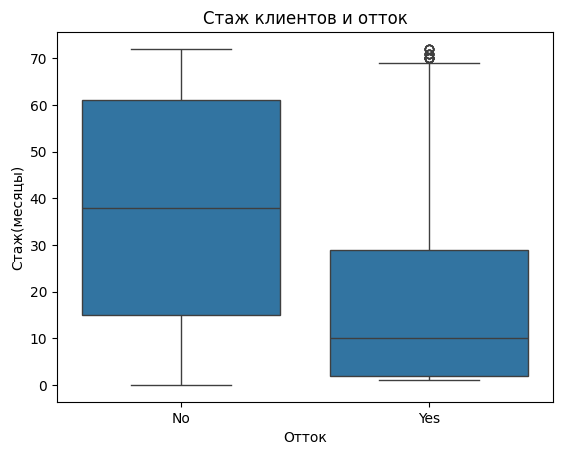

In [29]:
sns.boxplot(data=raw,x="Churn", y="tenure")
plt.title("Стаж клиентов и отток")
plt.xlabel("Отток")
plt.ylabel("Стаж(месяцы)")
plt.show

**Что видно на графике 4.** Клиенты с небольшим стажем чаще уходят.

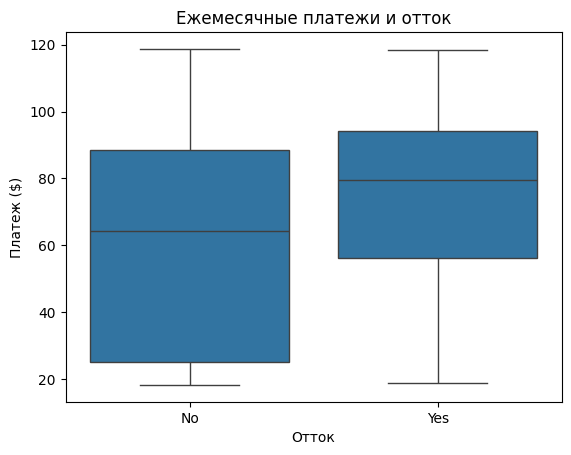

In [30]:
sns.boxplot(data=raw, x="Churn", y="MonthlyCharges")
plt.title("Ежемесячные платежи и отток")
plt.xlabel("Отток")
plt.ylabel("Платеж ($)")
plt.show()

**Что видно на графике 5.** Уходящие клиенты в среднем имеют более высокие ежемесячные платежи.

**Вывод по EDA.** 3-5 главных находок с числами.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [31]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()
    for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
      d[col] = pd.to_numeric(
d[col].astype(str).str.strip().replace("",None),
            errors = "coerce"

      )
    journal.append("Числовые столбцы преобразованы.")
    missing = d["TotalCharges"].isna().sum()
    d["TotalCharges"] = d["TotalCharges"].fillna(0)
    journal.append(f"Заполнено пропусков TotalCharges: {missing}.")

    assert(d["tenure"] >= 0).all()
    assert(d["MonthlyCharges"] >= 0).all()
    assert d["TotalCharges"].isna().sum() == 0
    journal.append("Проверены основные правила.")
    return d

In [32]:
# clean_df = clean(raw); сравнение с пошаговой очисткой; сторожа assert
journal = []
clean_df = clean(raw)
print(clean_df.head())
print("Пропуски:", clean_df.isna().sum().sum())
assert clean_df["TotalCharges"].isna().sum() == 0
assert (clean_df["tenure"] >= 0).all()
print("Проверка пройдена!")

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity  \
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No   
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes                No             DSL            Yes   
3  7795-CFOCW    Male              0      No         No      45           No  No phone service             DSL            Yes   
4  9237-HQITU  Female              0      No         No       2          Yes                No     Fiber optic             No   

  OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  \
0          Yes               No          No          No              No  Month-to-month   

In [33]:
# show_journal()
def show_journal():
  for item in journal:
    print("-", item)
show_journal()

- Числовые столбцы преобразованы.
- Заполнено пропусков TotalCharges: 0.
- Проверены основные правила.


In [34]:
Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/telco_clean.csv", index=False)
print("Файл успешно сохранен !")


Файл успешно сохранен !


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [35]:
TARGET = "Churn"

In [36]:
 selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
НЕТ  цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
НЕТ  в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 21


In [37]:
# ПОМОЩНИКИ ЭТАПА 2. Запустите после ячейки «Помощники» этапа 1.
import joblib
import sklearn
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder


def is_class(y):
    """Цель 0 и 1: классификация. Иначе регрессия."""
    return set(pd.Series(y).dropna().unique()) <= {0, 1}


def make_prep(num_cols, cat_cols=(), flag_cols=(), add_features=None, min_frequency=10, target_cols=(), y=None):
    """Вся подготовка одним объектом, как в части 5 практики занятия 12.

    num_cols: числа, заполняются медианой train и стандартизируются;
    flag_cols: флаги 0 и 1, идут как есть;
    cat_cols: категории, флаги через OneHotEncoder, редкие реже min_frequency в общий столбец;
    target_cols: категории с сотнями значений, кодирование по цели через TargetEncoder (нужен y);
    add_features: ваша функция признаков по одной строке, станет первым шагом.
    """
    branches = [(make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(num_cols))]
    if flag_cols:
        branches.append(("passthrough", list(flag_cols)))
    if cat_cols:
        branches.append((OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                       sparse_output=False), list(cat_cols)))
    if target_cols:
        branches.append((make_target_encoder(y), list(target_cols)))
    steps = [FunctionTransformer(add_features)] if add_features is not None else []
    return make_pipeline(*steps, make_column_transformer(*branches))


def make_target_encoder(y):
    """TargetEncoder с одинаковым результатом на любой версии scikit-learn."""
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    folds = StratifiedKFold if is_class(y) else KFold
    if version >= (1, 9):
        return TargetEncoder(cv=folds(5, shuffle=True, random_state=0))
    return TargetEncoder(random_state=0)


def make_model(prep, y):
    """Подготовка и простая модель в одном Pipeline: логистическая регрессия для классов, линейная для чисел."""
    model = LogisticRegression(solver="newton-cholesky") if is_class(y) else LinearRegression()
    return make_pipeline(prep, model)


def make_dummy(y):
    """Пустышка: самый частый класс или медиана."""
    return DummyClassifier(strategy="most_frequent") if is_class(y) else DummyRegressor(strategy="median")


def cv_score(model, X, y):
    """Кросс-валидация на train: доля верных для классов, MAE для чисел."""
    if is_class(y):
        return cross_val_score(model, X, y, cv=5, scoring="accuracy").mean()
    return -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error").mean()


def test_score(model, X_test, y_test):
    """Оценка на test: доля верных для классов, MAE для чисел. Вызывать один раз в конце."""
    prediction = model.predict(X_test)
    if is_class(y_test):
        return accuracy_score(y_test, prediction)
    return mean_absolute_error(y_test, prediction)


def ladder_plot(ladder, y, path=None):
    """График-лестница: пустышка первой ступенью. Заголовок-вывод считается сам."""
    names, values = list(ladder.index), list(ladder.values)
    if is_class(y):
        title = f"Модель лучше пустышки на {(max(values) - values[0]) * 100:.1f} процентного пункта"
        ylabel, fmt, low = "доля верных", "%.3f", 0.5 if min(values) > 0.5 else 0
    else:
        title = f"Модель ошибается на {(1 - min(values) / values[0]) * 100:.0f}% меньше пустышки"
        ylabel, fmt, low = "MAE, меньше лучше", "%.2f", 0
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    colors = [GRAY] + [TEAL] * (len(values) - 1)
    bars = ax.bar(names, values, color=colors)
    ax.bar_label(bars, fmt=fmt, padding=2)
    ax.set_ylim(low, max(values) * 1.12)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(names) > 4:
        plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=120)
    plt.show()


def write_requirements(path="requirements.txt"):
    """requirements.txt с версиями библиотек этой среды."""
    import matplotlib
    lines = [f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"scikit-learn=={sklearn.__version__}",
             f"matplotlib=={matplotlib.__version__}", f"joblib=={joblib.__version__}"]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))


print("помощники этапа 2 готовы")

помощники этапа 2 готовы


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [38]:
# 1. Количество подключённых услуг
service_cols = [
    "PhoneService", "MultipleLines", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies"
]

clean_df["TotalServices"] = (clean_df[service_cols] == "Yes").sum(axis=1)

# 2. Долгосрочный клиент (24 месяца и больше)
clean_df["IsLongTermCustomer"] = (clean_df["tenure"] >= 24).astype(int)

# 3. Средняя ежемесячная плата за весь период
clean_df["AvgMonthlyPerTenure"] = (
    clean_df["TotalCharges"] / clean_df["tenure"].replace(0, 1)
)

clean_df[[
    "TotalServices",
    "IsLongTermCustomer",
    "AvgMonthlyPerTenure"
]].head()

,TotalServices,IsLongTermCustomer,AvgMonthlyPerTenure
0,1,0,29.850000
1,3,1,55.573529
2,3,0,54.075000
3,3,1,40.905556
4,1,0,75.825000


## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [39]:
# Объединяем редкие категории в Other

X = clean_df.drop(columns=["Churn", "customerID"])
y = clean_df["Churn"].map({"No": 0, "Yes": 1})

for col in X.select_dtypes(include="object").columns:
    freq = X[col].value_counts()
    rare = freq[freq < 50].index
    X[col] = X[col].replace(rare, "Other")

# Преобразуем категории в числовые признаки
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Проверяем результат
print("Размер таблицы:", X.shape)
print("Пропуски:", X.isna().sum().sum())
print("Только числа:", X.select_dtypes(exclude="number").shape[1] == 0)

X.head()

Размер таблицы: (7043, 33)
Пропуски: 0
Только числа: True


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,TotalServices,IsLongTermCustomer,AvgMonthlyPerTenure,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,1,0,29.850000,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,3,1,55.573529,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,3,0,54.075000,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,3,1,40.905556,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,75.825000,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [40]:
# Проверка утечки данных

leakage_table = pd.DataFrame({
    "Столбец": ["Churn", "customerID", "TotalCharges",
                "tenure", "MonthlyCharges"],
    "Когда известен": [
        "После ухода или решения клиента",
        "При регистрации клиента",
        "Во время обслуживания",
        "Во время обслуживания",
        "При выставлении счёта"
    ],
    "Используем": ["Нет", "Нет", "Да", "Да", "Да"]
})

display(leakage_table)

,Столбец,Когда известен,Используем
0,Churn,После ухода или решения клиента,Нет
1,customerID,При регистрации клиента,Нет
2,TotalCharges,Во время обслуживания,Да
3,tenure,Во время обслуживания,Да
4,MonthlyCharges,При выставлении счёта,Да


## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [41]:
from sklearn.model_selection import train_test_split

# Признаки и целевая переменная
X_model = clean_df.drop(columns=["Churn", "customerID"])
y_model = clean_df["Churn"].map({"No": 0, "Yes": 1})

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model,
    test_size=0.2,
    random_state=42,
    stratify=y_model
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5634, 22)
Test: (1409, 22)


In [42]:
# Базовая модель Dummy

dummy_model = make_dummy(y_train)

dummy_score = cv_score(
    dummy_model,
    X_train,
    y_train
)

print("Dummy accuracy:", round(dummy_score, 4))

Dummy accuracy: 0.7346


In [43]:
# Простая модель на 5 признаках

simple_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen",
    "TotalServices"
]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "TotalServices"]
flag_cols = ["SeniorCitizen"]

simple_prep = make_prep(
    num_cols=num_cols,
    flag_cols=flag_cols
)

simple_model = make_model(simple_prep, y_train)

simple_score = cv_score(
    simple_model,
    X_train[simple_cols],
    y_train
)

print("Simple model accuracy:", round(simple_score, 4))

Simple model accuracy: 0.7934


In [44]:
# Полная модель

num_cols = [
    "tenure", "MonthlyCharges", "TotalCharges",
    "TotalServices", "AvgMonthlyPerTenure"
]

flag_cols = ["SeniorCitizen", "IsLongTermCustomer"]

cat_cols = [
    col for col in X_train.select_dtypes(include="object").columns
]

full_prep = make_prep(
    num_cols=num_cols,
    cat_cols=cat_cols,
    flag_cols=flag_cols
)

full_model = make_model(full_prep, y_train)

full_score = cv_score(
    full_model,
    X_train,
    y_train
)

print("Full model accuracy:", round(full_score, 4))

Full model accuracy: 0.8055


In [45]:
# Финальная проверка на Test

full_model.fit(X_train, y_train)

test_result = test_score(
    full_model,
    X_test,
    y_test
)

print("Test accuracy:", round(test_result, 4))

Test accuracy: 0.807


## 14. Выводы

Датасет содержит 7043 записи о клиентах.



Клиенты с помесячным контрактом чаще уходят.



Небольшой стаж клиента связан с более высоким риском ухода.



Полная модель показала Accuracy 80,55% на обучении и 80,7% на тесте.



В дальнейшем можно улучшить модель, подобрать параметры и проверить другие алгоритмы.

## 15. README

# Telco Customer Churn Prediction

## 1. Описание проекта
Цель проекта - предсказать, уйдёт ли клиент телекоммуникационной компании (Churn).

## 2. Данные
Использован датасет Telco Customer Churn.
Количество записей: 7043
Количество столбцов: 21
Целевая переменная: Churn

## 3. Подготовка данных
Проверены пропуски и дубликаты.
Исправлены типы данных.
Созданы новые признаки.
Категориальные признаки преобразованы в числовые.

## 4. Моделирование
Построены Dummy, Simple и Full модели. Для оценки использовались обучающая и тестовая выборки.

## 5. Результаты
Dummy Accuracy: 73,46%

Simple Model Accuracy: 79,34%

Full Model Accuracy: 80,55%

Test Accuracy: 80,7%

## 6. Вывод
Полная модель показала лучший результат. Её можно использовать как основу для дальнейшего улучшения прогнозирования оттока клиентов.

In [46]:
# этап 2

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.